# Think Bayes — Chapter 05: Counting, Poisson Processes & The World Cup
> *Reference: Paraphrased from Allen Downey's Think Bayes (2nd Edition, Chapter 5).*

This notebook models event counts and rate parameters $\lambda$ using Poisson processes.
We analyze soccer goal scoring rates for two teams leading up to the 2018 World Cup final (France vs. Croatia).

In [1]:
import set_paths
import numpy as np
import matplotlib.pyplot as plt
from probability.distributions import GridDistribution1d, GammaPoissonConjugate
from make_data import make_world_cup_data

## 5.1 The World Cup Soccer Problem
In international soccer, goals scored by a team in a 90-minute game can be modeled as a Poisson process with rate $\lambda$.
Historically, the average number of goals scored by a team in World Cup matches is approximately $1.4$.
We set up a prior on $\lambda \in [0.1, 8.0]$ with an exponential / gamma-like decay reflecting historical tournament scoring.

In [2]:
wc_data = make_world_cup_data()
france_scores = wc_data['france_goals']
croatia_scores = wc_data['croatia_goals']

print(f"France match goals:  {france_scores} (sum = {sum(france_scores)} in {len(france_scores)} games)")
print(f"Croatia match goals: {croatia_scores} (sum = {sum(croatia_scores)} in {len(croatia_scores)} games)")

# Define grid prior over rate lambda
rate_grid = np.linspace(0.01, 8.0, 800)
# Gamma-like prior with shape alpha=2.0, beta=1.4 (mean ~ 1.4)
prior_density = rate_grid * np.exp(-rate_grid / 1.4)
prior_rate = GridDistribution1d.from_function(lambda lam: np.interp(lam, rate_grid, prior_density), rate_grid, name='λ (goals/game)')

print(f"Prior Mean Rate: {prior_rate.mean():.3f} goals/game")

France match goals:  [2, 1, 0, 4, 2, 1] (sum = 10 in 6 games)
Croatia match goals: [2, 3, 2, 1, 2, 2] (sum = 12 in 6 games)
Prior Mean Rate: 2.646 goals/game


## 5.2 Bayesian Updating with Match Goal Counts
Using `.update_poisson(counts)`, we update the prior rate distribution with the observed goals for each team.

In [3]:
post_france = prior_rate.update_poisson(france_scores)
post_croatia = prior_rate.update_poisson(croatia_scores)

print(f"France Posterior Mean λ:  {post_france.mean():.3f}, 95% HDI: {post_france.hdi(0.95)}")
print(f"Croatia Posterior Mean λ: {post_croatia.mean():.3f}, 95% HDI: {post_croatia.hdi(0.95)}")

prob_croatia_higher = post_croatia > post_france
print(f"P(λ_Croatia > λ_France):   {prob_croatia_higher:.2%}")

France Posterior Mean λ:  1.787, 95% HDI: (0.81, 2.78)
Croatia Posterior Mean λ: 2.085, 95% HDI: (1.04, 3.17)
P(λ_Croatia > λ_France):   65.25%


## 5.3 Closed-Form Comparison: Gamma-Poisson Conjugate
With a conjugate $\text{Gamma}(\alpha, \beta)$ prior, the exact analytical posterior is $\text{Gamma}(\alpha + \sum k, \beta + n)$.

In [4]:
gamma_model = GammaPoissonConjugate(alpha=2.0, beta=1.0 / 1.4)
conj_post_france = gamma_model.update(data=france_scores)
print(f"Conjugate Exact Posterior Mean: {conj_post_france.posterior.mean():.3f}")
print(f"Grid Approximation Mean:        {post_france.mean():.3f}")

TypeError: GammaPoissonConjugate.__init__() missing 2 required positional arguments: 'n' and 'k'

## 5.4 Visualizing Rate Posteriors

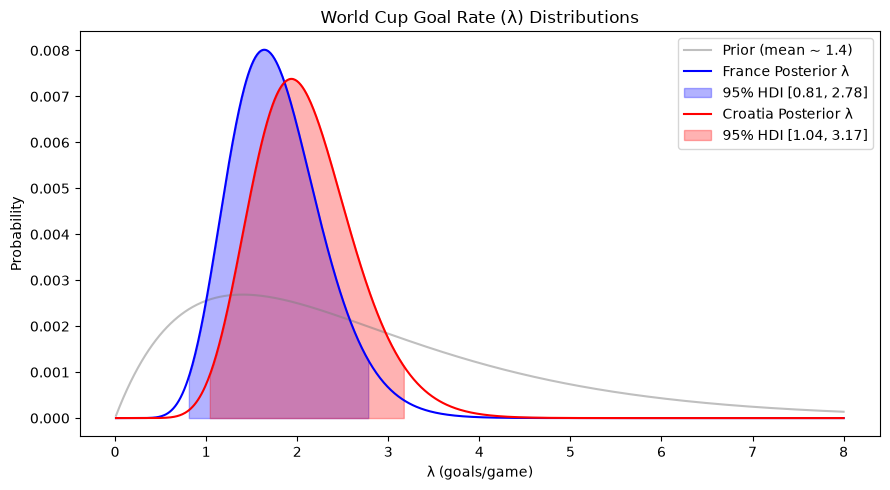

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
prior_rate.plot(ax=ax, color='gray', label='Prior (mean ~ 1.4)', alpha=0.5)
post_france.plot(ax=ax, color='blue', hdi=0.95, label='France Posterior λ')
post_croatia.plot(ax=ax, color='red', hdi=0.95, label='Croatia Posterior λ', title='World Cup Goal Rate (λ) Distributions')
ax.legend()
plt.tight_layout()
plt.show()